# Лабораторная работа № 1. Численное дифференцирование

*Цель*: сравнить абсолютные погрешности пяти формул численного вычисления первой производной и исследовать влияние шага.

Используем шаги $h_n=2/2^n$, $n=1,\ldots,21$: от $1$ до $2^{-20}\approx9.537\cdot10^{-7}$. Для каждой функции строим отдельный рисунок с пятью линиями. Обе оси имеют логарифмический масштаб.

Точка вычисления: $x=0.5$. Её можно изменить в переменной X ниже. Для заданного набора шагов и всех пяти функций нужно $X>0$: при максимальном сдвиге $-3h$ аргумент логарифма должен оставаться положительным.

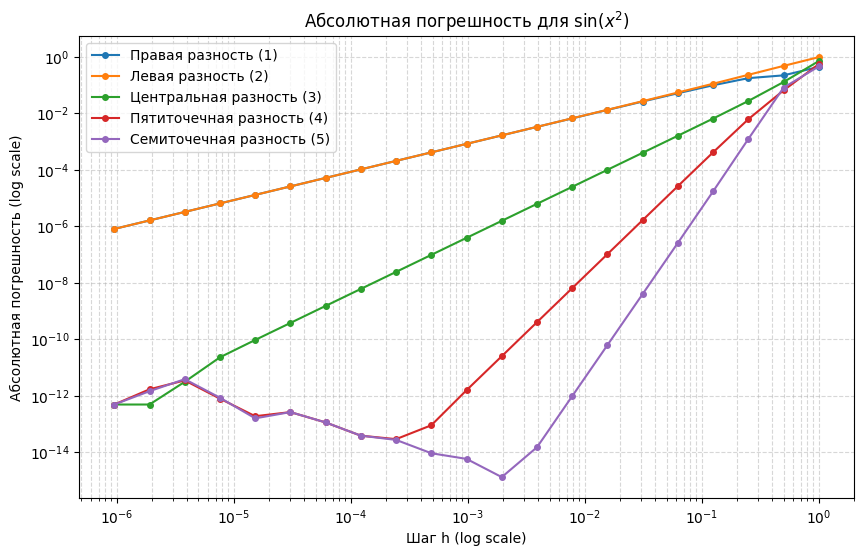

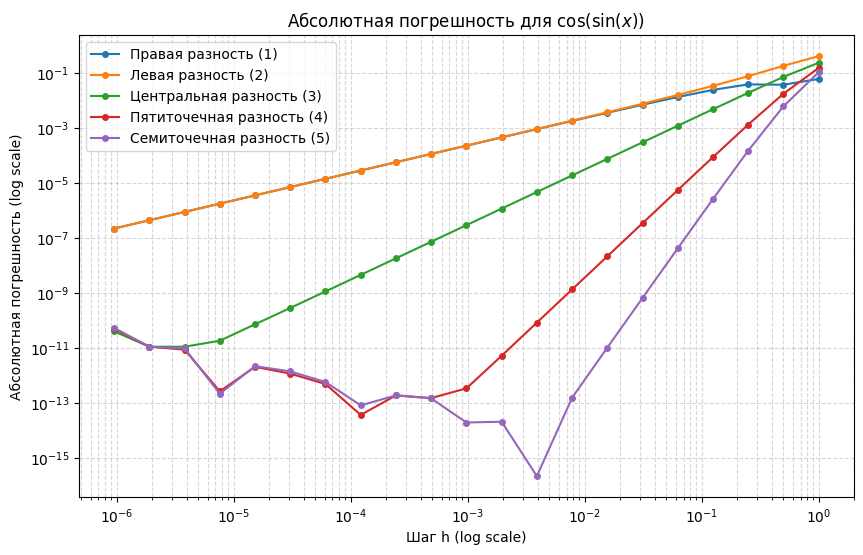

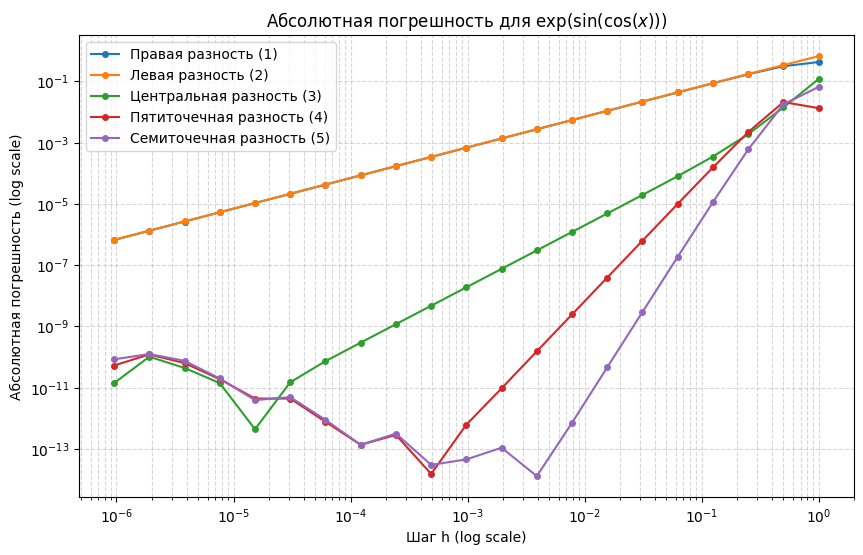

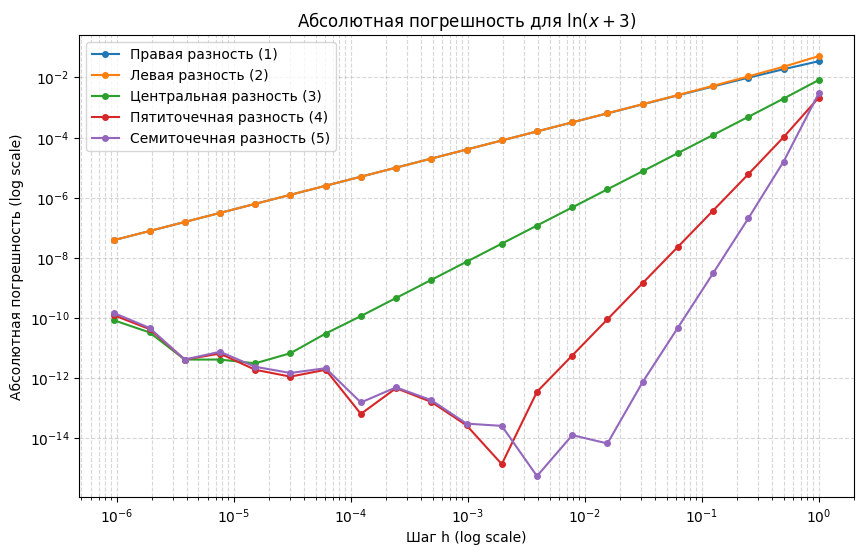

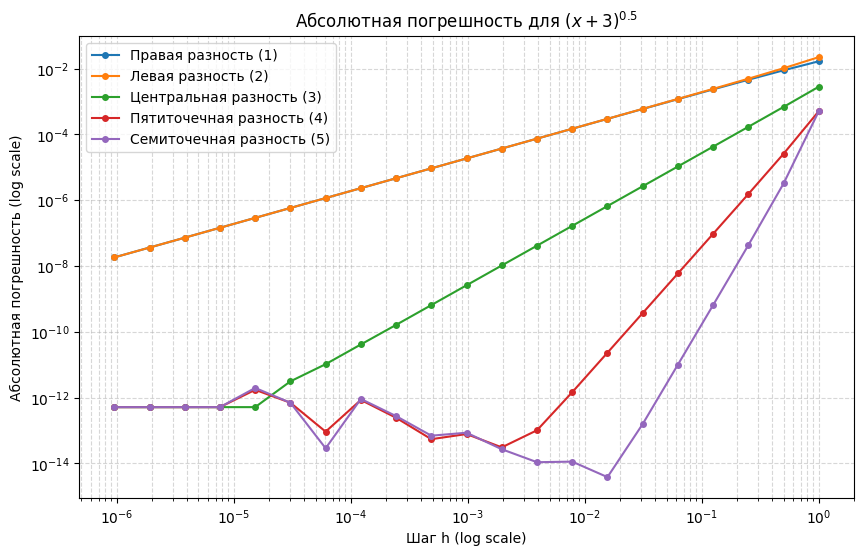

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# functions

def f1(x):  return np.sin(x**2)
def df1(x): return 2*x*np.cos(x**2)

def f2(x):  return np.cos(np.sin(x))
def df2(x): return -np.cos(x)*np.sin(np.sin(x))

def f3(x):  return np.exp(np.sin(np.cos(x)))
def df3(x): return -np.sin(x)*np.cos(np.cos(x))*np.exp(np.sin(np.cos(x)))

def f4(x):  return np.log(x + 3)
def df4(x): return 1.0 / (x + 3)

def f5(x):  return (x + 3)**0.5
def df5(x): return 0.5 / np.sqrt(x + 3)

functions = [
    (f1, df1, r'$\sin(x^2)$'),
    (f2, df2, r'$\cos(\sin(x))$'),
    (f3, df3, r'$\exp(\sin(\cos(x)))$'),
    (f4, df4, r'$\ln(x+3)$'),
    (f5, df5, r'$(x+3)^{0.5}$')
]

# parameters

x0 = 0.5
n_range = np.arange(1, 22)
h_values = 2.0 / (2.0**n_range)

# methods

def method_1(f, x, h):
    return (f(x + h) - f(x)) / h

def method_2(f, x, h):
    return (f(x) - f(x - h)) / h

def method_3(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

def method_4(f, x, h):
    term1 = (f(x + h) - f(x - h)) / (2 * h)
    term2 = (f(x + 2*h) - f(x - 2*h)) / (4 * h)
    return (4/3) * term1 - (1/3) * term2

def method_5(f, x, h):
    term1 = (f(x + h) - f(x - h)) / (2 * h)
    term2 = (f(x + 2*h) - f(x - 2*h)) / (4 * h)
    term3 = (f(x + 3*h) - f(x - 3*h)) / (6 * h)
    return (3/2) * term1 - (3/5) * term2 + (1/10) * term3

methods = [method_1, method_2, method_3, method_4, method_5]
method_labels = [
    'Правая разность (1)',
    'Левая разность (2)',
    'Центральная разность (3)',
    'Пятиточечная разность (4)',
    'Семиточечная разность (5)'
]

# plots

for f, df, title in functions:
    plt.figure(figsize=(10, 6))

    exact_val = df(x0)

    for method, label in zip(methods, method_labels):
        errors = []
        for h in h_values:
            try:
                approx_val = method(f, x0, h)
                error = abs(approx_val - exact_val)
                errors.append(error)
            except Exception as e:
                errors.append(np.nan)

        plt.loglog(h_values, errors, marker='o', label=label, markersize=4)

    plt.title(f'Абсолютная погрешность для {title}')
    plt.xlabel('Шаг h (log scale)')
    plt.ylabel('Абсолютная погрешность (log scale)')
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend()
    plt.show()